## Ćwiczenie 10: Region growing

### Cel ćwiczenia
Celem tego ćwiczenia jest zrozumienie i samodzielne zaimplementowanie algorytmu rozrostu obszaru (Region Growing) od zera, bez użycia gotowych funkcji z bibliotek. W ramach optymalizacji wykorzystamy strukturę kolejki (przeszukiwanie wszerz - BFS), aby zapobiec problemom z limitami rekurencji w Pythonie, które często występują przy dużych obrazach medycznych.

---

### Wstęp Teoretyczny

**Rozrost obszaru (Region Growing)** to klasyczna, oddolna metoda segmentacji obrazów. Należy do grupy algorytmów opartych na regionach, w których głównym założeniem jest to, że sąsiednie piksele należące do tego samego obiektu mają podobne właściwości (najczęściej jasność/intensywność).

#### Sposób działania:
1. **Punkt startowy (Seed Point):** Algorytm rozpoczyna działanie od jednego lub kilku punktów początkowych, które na pewno należą do interesującego nas obiektu (np. środek tkanki guza).
2. **Analiza sąsiedztwa:** Algorytm bada sąsiednie piksele wokół obszaru startowego.
   * **4-sąsiedztwo:** Piksele przylegające bezpośrednio krawędziami (góra, dół, lewo, prawo).
   * **8-sąsiedztwo:** Piksele przylegające krawędziami oraz po skosie (rogi).
3. **Kryterium podobieństwa (Homogeneity Criterion):** Piksel sąsiedni jest dołączany do regionu, jeśli spełnia określony warunek. Najprostszym warunkiem jest maksymalna różnica jasności ($T$) względem punktu początkowego ($I_{seed}$):
   $$ \bigl| I(y, x) - I_{seed} \bigr| \le T $$
4. **Kryterium stopu:** Rozrost kończy się, gdy nie ma już żadnych sąsiednich pikseli spełniających kryterium dołączenia.

#### Problem wycieku (Leakage)
Wadą tej metody jest podatność na szum oraz niewyraźne, rozmyte krawędzie. Jeśli próg $T$ będzie zbyt duży, lub przejście między obiektem a tłem będzie łagodne, maska "wycieknie" poza obiekt i obejmie niepożądane tło. Rozwiążemy ten problem w Zadaniu 2, dobierając odpowiednie parametry na zaszumionym obrazie.

#### Pseudokod:

FUNKCJA region_growing(obraz, punkt_startowy, próg_odchylenia):

    # KROK 1: Inicjalizacja
    STWÓRZ pustą maskę (początkowo same zera/fałsz, wielkość taka jak 'obraz')
    STWÓRZ tablicę 'odwiedzone' (początkowo same zera/fałsz, wielkość taka jak 'obraz')
    
    POBIERZ jasność_startową z 'obraz' w miejscu 'punkt_startowy'
    
    STWÓRZ pustą KOLEJKĘ (działającą na zasadzie FIFO - pierwszy wszedł, pierwszy wyszedł)
    DODAJ 'punkt_startowy' do KOLEJKI
    OZNACZ 'punkt_startowy' w tablicy 'odwiedzone' jako PRAWDA

    # KROK 2: Główna pętla rozrostu (dopóki są piksele do sprawdzenia)
    DOPÓKI KOLEJKA nie jest pusta:
        
        # Wyciągamy pierwszy piksel czekający w kolejce
        AKTUALNY_PIKSEL = WYCIĄGNIJ z KOLEJKI
        
        # Zaznaczamy go jako część naszego wyodrębnionego obiektu
        OZNACZ AKTUALNY_PIKSEL w 'maska' jako PRAWDA
        
        # Sprawdzamy wszystkich 4 sąsiadów wokół wyciągniętego piksela
        DLA KAŻDEGO (sąsiada wokół AKTUALNY_PIKSEL):
            
            # Warunek 1: Czy sąsiad nie wychodzi poza krawędź obrazka?
            JEŚLI sąsiad_mieści_się_w_granicach_obrazu:
                
                # Warunek 2: Czy ten piksel nie był już wcześniej sprawdzany?
                JEŚLI sąsiad_w_tablicy_odwiedzone == FAŁSZ:
                    
                    # Od razu oznaczamy go jako odwiedzony, by nie sprawdzać go dwa razy
                    OZNACZ sąsiad w tablicy 'odwiedzone' jako PRAWDA
                    
                    # Warunek 3: KRYTERIUM PODOBIEŃSTWA (Porównanie jasności z punktem startowym)
                    jasność_sąsiada = POBIERZ jasność z 'obraz' dla sąsiad
                    różnica = WARTOŚĆ BEZWZGLĘDNA(jasność_sąsiada - jasność_startowa)
                    
                    JEŚLI różnica <= próg_odchylenia:
                        # Sąsiad jest wystarczająco podobny! 
                        # Dodajemy go na koniec kolejki, żeby w przyszłości sprawdzić też jego sąsiadów.
                        DODAJ sąsiad do KOLEJKI
                        
    # KROK 3: Zakończenie
    # Kolejka pusta, nie ma już pikseli spełniających warunki obok siebie.
    ZWRÓĆ maska

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from matplotlib.animation import FuncAnimation, PillowWriter

In [25]:
# 1. Generowanie mniejszego obrazu testowego (aby animacja była czytelna i szybka)
np.random.seed(42)
img_size = 60
img_test = np.zeros((img_size, img_size))
img_test[15:45, 15:45] = 0.8  # Kwadrat w środku
img_test += np.random.normal(0, 0.08, (img_size, img_size)) # Szum Gaussa
img_test = np.clip(img_test, 0, 1)

seed_point = (30, 30)
threshold_val = 0.15

# 2. Inicjalizacja zmiennych dla algorytmu Region Growing
height, width = img_test.shape
segmented = np.zeros((height, width), dtype=bool)
visited = np.zeros((height, width), dtype=bool)

seed_y, seed_x = seed_point
seed_val = float(img_test[seed_y, seed_x])

queue = deque([(seed_y, seed_x)])
visited[seed_y, seed_x] = True
neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

# Tablica do przechowywania historii rozrostu (klatek animacji)
frames = []
frames.append(segmented.copy())

iteration = 0

# 3. Zmodyfikowana pętla algorytmu zapisująca stan maski w trakcie pracy
while queue:
    y, x = queue.popleft()
    segmented[y, x] = True
    
    for dy, dx in neighbors:
        ny, nx = y + dy, x + dx
        
        if 0 <= ny < height and 0 <= nx < width:
            if not visited[ny, nx]:
                visited[ny, nx] = True
                
                if abs(float(img_test[ny, nx]) - seed_val) <= threshold_val:
                    queue.append((ny, nx))
                    
    iteration += 1
    # Zapisujemy klatkę co 5 iteracji, żeby przyspieszyć renderowanie i odtwarzanie animacji
    if iteration % 5 == 0:
        frames.append(segmented.copy())

# Zapisujemy ostatnią klatkę powieloną kilka razy
for _ in range(10):  # Powielamy na koniec, żeby animacja na chwilę zatrzymała się na wyniku
    frames.append(segmented.copy())

# 4. Tworzenie animacji z wykorzystaniem Matplotlib
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img_test, cmap='gray')

# Inicjalizacja pustej warstwy maski (w formacie RGBA)
rgba = np.zeros((height, width, 4))
mask_layer = ax.imshow(rgba)
ax.axis('off')

# Funkcja aktualizująca wygląd pojedynczej klatki
def update(frame_idx):
    mask = frames[frame_idx]
    
    # Odświeżenie kanałów RGBA
    current_rgba = np.zeros((height, width, 4))
    current_rgba[mask, 0] = 1.0  # Czerwony kolor (kanał R)
    current_rgba[mask, 3] = 0.6  # Przezroczystość 60% (kanał Alpha)
    
    mask_layer.set_data(current_rgba)
    
    # Podpis z przybliżoną iteracją
    current_iter = min((frame_idx * 5), iteration)
    ax.set_title(f"Algorytm Region Growing\nRozrost maski (Iteracja: {current_iter})", fontsize=14)
    return [mask_layer]

# Złożenie klatek w animację
ani = FuncAnimation(fig, update, frames=len(frames), blit=True)

# Opcjonalnie: Zapis do pliku GIF (wymaga biblioteki Pillow)
# ani.save("region_growing_animation.gif", writer=PillowWriter(fps=20))

from IPython.display import HTML

# Złożenie klatek w animację
ani = FuncAnimation(fig, update, frames=len(frames), blit=True)

# Zamykamy standardowy, statyczny wykres, aby nie wyświetlał się podwójnie
plt.close(fig)

# Wyświetlamy animację jako interaktywny odtwarzacz wideo w komórce
HTML(ani.to_jshtml())

### Zadanie 1: Funkcja Region Growing

Uzupełnij poniższą funkcję. Zaimplementuj kryterium podobieństwa oraz przeszukiwanie 4-sąsiedztwa.

In [12]:
import numpy as np
from collections import deque

def region_growing(img, seed, threshold):
    """
    Segmentacja metodą rozrostu obszaru (Region Growing).

    Algorytm bada piksele wokół punktu startowego (seed) i dołącza je do wyodrębnionego
    regionu (maski), jeśli różnica ich jasności względem piksela startowego nie przekracza
    zadanego progu (threshold). Przeszukiwanie odbywa się z wykorzystaniem kolejki (algorytm BFS).

    :param img: Dwuwymiarowa tablica NumPy (obraz w odcieniach szarości).
    :param seed: Krotka (y, x) wyznaczająca punkt startowy na obrazie.
    :param threshold: Maksymalna dopuszczalna różnica jasności (wartość bezwzględna).
    :return: Dwuwymiarowa tablica NumPy typu bool (maska binarna z wyodrębnionym obiektem).
    """
    
    # 1. Pobranie wymiarów obrazu, abyśmy nie wyszli poza jego granice w trakcie rozrostu.
    height, width = img.shape
    
    # 2. Inicjalizacja pustych tablic:
    # 'segmented' to ostateczna maska z wyodrębnionym obiektem (True = obiekt, False = tło)
    segmented = np.zeros((height, width), dtype=bool)
    # 'visited' przechowuje informacje o tym, które piksele już sprawdziliśmy, żeby się nie zapętlić
    visited = np.zeros((height, width), dtype=bool)

    # 3. Pobranie współrzędnych punktu startowego oraz jego jasności (referencji)
    seed_y, seed_x = seed
    seed_val = float(img[seed_y, seed_x])

    # 4. Inicjalizacja struktury kolejki. Używamy 'deque' (dwustronnej kolejki z modułu collections),
    # ponieważ dodawanie i usuwanie elementów na jej końcach jest znacznie szybsze niż w standardowej liście.
    queue = deque([(seed_y, seed_x)])
    
    # Odznaczamy punkt startowy jako odwiedzony (żeby nie wrzucić go do kolejki drugi raz)
    visited[seed_y, seed_x] = True

    # 5. Definiujemy 4-sąsiedztwo (przesunięcia względem aktualnego punktu)
    # (dy, dx): 
    # (-1, 0) to sąsiad z góry
    # (1, 0)  to sąsiad z dołu
    # (0, -1) to sąsiad z lewej
    # (0, 1)  to sąsiad z prawej
    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)] 

    # 6. Główna pętla rozrostu algorytmu BFS (Breadth-First Search - przeszukiwanie wszerz)
    # Wykonuje się dopóki w kolejce są jakiekolwiek współrzędne pikseli do sprawdzenia
    while queue:
        # Pobieramy pierwszy piksel z lewej strony kolejki
        y, x = queue.popleft()
        
        # Wiemy, że piksele, które trafiły do kolejki, spełniły już kryteria (lub są punktem startowym).
        # Dlatego od razu zaznaczamy go jako część obiektu.
        segmented[y, x] = True
        
        # 7. Iterujemy po wszystkich sąsiadach aktualnego piksela
        for dy, dx in neighbors:
            ny, nx = y + dy, x + dx  # (ny, nx) to nowa pozycja sąsiada
            
            # Sprawdzamy czy nowa pozycja (sąsiad) w ogóle znajduje się na obrazku
            if 0 <= ny < height and 0 <= nx < width:
                
                # Jeśli piksel nie był jeszcze sprawdzany przez algorytm
                if not visited[ny, nx]:
                    # Natychmiast zaznaczamy go jako odwiedzony, by żaden inny sąsiad go nie dodał
                    visited[ny, nx] = True
                    
                    # 8. KRYTERIUM PODOBIEŃSTWA (Homogeneity Criterion)
                    # Obliczamy bezwzględną różnicę pomiędzy sprawdzanym pikselem a punktem referencyjnym (seed)
                    # Jeśli różnica ta jest mniejsza bądź równa threshold, to ten piksel stanowi 
                    # jednorodną całość z obiektem, więc dokładamy go na koniec kolejki (czeka na swoją kolej).
                    if abs(float(img[ny, nx]) - seed_val) <= threshold:
                        queue.append((ny, nx))

    # Po opróżnieniu kolejki (brak nowych pikseli spełniających kryteria), zwracamy gotową maskę.
    return segmented

### Zadanie 2: Testowanie na figurze geometrycznej z szumem

Uruchom poniższy kod, aby wygenerować obraz testowy (kwadrat na tle) z dodanym szumem Gaussa. Następnie przetestuj swoją funkcję dla różnych współrzędnych `seed_point` i wartości `threshold`, i dobierz je tak, aby optymalnie wyodrębnić sam kwadrat.

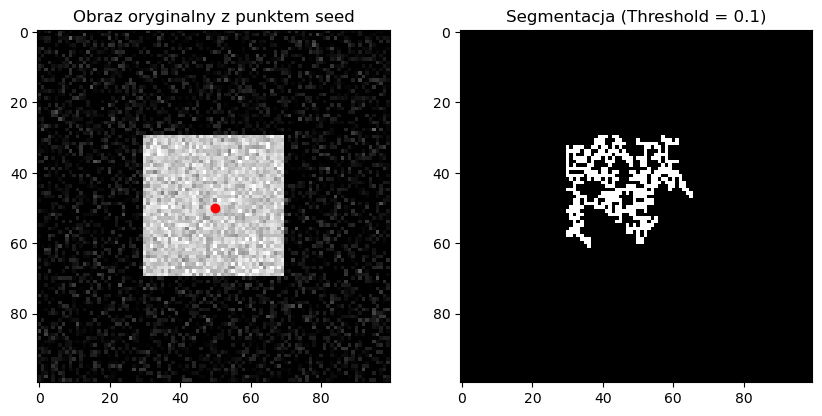

In [19]:
# Generowanie obrazu testowego
np.random.seed(42)
img_test = np.zeros((100, 100))
img_test[30:70, 30:70] = 0.8  # Kwadrat o jasności 0.8
img_test += np.random.normal(0, 0.1, (100, 100))  # Dodanie szumu Gaussa
img_test = np.clip(img_test, 0, 1)

# TODO: Ustaw punkt startowy wewnątrz kwadratu (y, x)
seed_point = (50, 50) 
# TODO: Poeksperymentuj z wartością threshold, aby wyodrębnić cały kwadrat, ale bez szumu z tła
threshold_val = 0.1 

# Wywołanie funkcji
mask = region_growing(img_test, seed_point, threshold_val)

# Wizualizacja
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img_test, cmap='gray')
ax[0].plot(seed_point[1], seed_point[0], 'ro')
ax[0].set_title('Obraz oryginalny z punktem seed')
ax[1].imshow(mask, cmap='gray')
ax[1].set_title(f'Segmentacja (Threshold = {threshold_val})')
plt.show()